# Dependecides

In [154]:
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt, seaborn as sns

# Import Dataset

In [155]:
columns = ['country', 'weight', 'age', 'age_australia', 'ai_heard', 'ai_cncexc', 'aireg_us', 'aireg_china', 'aireg_eu', 'aireg_country', 'd_educ_argentina', 'd_educ_australia', 'd_educ_brazil', 'd_educ_canada', 'd_educ_france', 'd_educ_germany','d_educ_germany_vocational', 'd_educ_greece', 'd_educ_hungary', 'd_educ_india', 'd_educ_indonesia', 'd_educ_israel', 'd_educ_israel_vocational', 'd_educ_italy', 'd_educ_japan', 'd_educ_kenya', 'd_educ_mexico', 'd_educ_netherlands', 'd_educ_nigeria', 'd_educ_poland', 'd_educ_safrica', 'd_educ_skorea', 'd_educ_spain', 'd_educ_sweden', 'd_educ_turkey', 'd_educ_uk']
df = pd.read_csv('Pew Research Center Global Attitudes Spring 2025 Dataset CSV.csv', usecols=columns, low_memory=False)



In [156]:
df.head()

,country,weight,ai_heard,ai_cncexc,aireg_us,aireg_china,aireg_eu,aireg_country,age,age_australia,...,d_educ_mexico,d_educ_netherlands,d_educ_nigeria,d_educ_poland,d_educ_safrica,d_educ_skorea,d_educ_spain,d_educ_sweden,d_educ_turkey,d_educ_uk
0,2,0.592005,2,2,2,8,2,2,77,,...,,,,,,,,,,
1,2,0.446814,2,3,4,4,2,2,72,,...,,,,,,,,,,
2,2,1.120110,2,2,4,4,8,2,74,,...,,,,,,,,,,
3,2,0.695317,2,2,4,4,1,2,78,,...,,,,,,,,,,
4,2,0.369352,1,3,3,3,2,2,67,,...,,,,,,,,,,


# Preprocessing

## Data Transformation

Map country codes to their actual country name

ie 1 -> US

In [157]:
country_codes = {1: "U.S.",
                2: "Canada",
                3: "France",
                4: "Germany",
                5: "Greece",
                6: "Hungary",
                7: "Italy",
                8: "Netherlands",
                9: "Poland",
                10: "Spain", 
                11: "Sweden",
                12: "UK",
                13: "Australia",
                14: "India",
                15: "Indonesia",
                16: "Japan",
                17: "South Korea",
                18: "Israel",
                19: "Turkey",
                20: "Kenya",
                21: "Nigeria",
                22: "South Africa",
                23: "Argentina",
                24: "Brazil",
                25: "Mexico"}

for c in columns:
    if c != 'country':
        df[c] = pd.to_numeric(df[c], errors='coerce')
df['country_name'] = df['country'].map(country_codes)

Keep raw copies of Q30 and Q31 before recoding

In [158]:
# Keep raw copies of Q30 and Q31 before recoding
df['ai_heard_raw'] = df['ai_heard']
df['ai_cncexc_raw'] = df['ai_cncexc']

Replace numerical codes representing missing responses (e.g. "Don't know" or "Refused") with Non Response.

In [159]:
for c in columns:
    if c != 'country' and c != 'weight':
        if c == 'd_educ_argentina':
            missing_codes = [98, 99]
        elif c.startswith('aireg_'):
            missing_codes = [9, 98, 99]
        elif c == 'age':
            missing_codes = [98, 99]
        else:
            missing_codes = [8, 9, 98, 99]
        df[c] = df[c].replace(missing_codes, "DK/Refused")

## Data Cleaning

### Investigating missing values

Checking what columns have missing values.

In [160]:
col_header = df.keys()
null_cols = []

for key in col_header:
    current_null_count =  df[key].isna().sum()

    if current_null_count != 0:
        null_cols.append(key)


print(f"The number of columns that have null values are {len(null_cols)}.")

if len(null_cols) != 0:
    print("The columns with null values are: \n")

    for key in null_cols:
        print(f"{key} with {df[key].isna().sum()} null values")


The number of columns that have null values are 28.
The columns with null values are: 

age with 1829 null values
age_australia with 26506 null values
d_educ_argentina with 27332 null values
d_educ_australia with 26512 null values
d_educ_brazil with 27280 null values
d_educ_canada with 27309 null values
d_educ_france with 27327 null values
d_educ_germany with 27327 null values
d_educ_germany_vocational with 27327 null values
d_educ_greece with 27323 null values
d_educ_hungary with 27313 null values
d_educ_india with 24788 null values
d_educ_indonesia with 27311 null values
d_educ_israel with 27335 null values
d_educ_israel_vocational with 27335 null values
d_educ_italy with 27326 null values
d_educ_japan with 27327 null values
d_educ_kenya with 27284 null values
d_educ_mexico with 27283 null values
d_educ_netherlands with 27333 null values
d_educ_nigeria with 27296 null values
d_educ_poland with 27331 null values
d_educ_safrica with 26763 null values
d_educ_skorea with 27291 null value

We can see that there's 28 columns that have null values and from those 28 we can form 2 groups to investiage futher being:

- age
- education


To get a better sense of what's causing the missing values we can use plots to see the relvent column's distrubtions.

In [161]:
%matplotlib inline

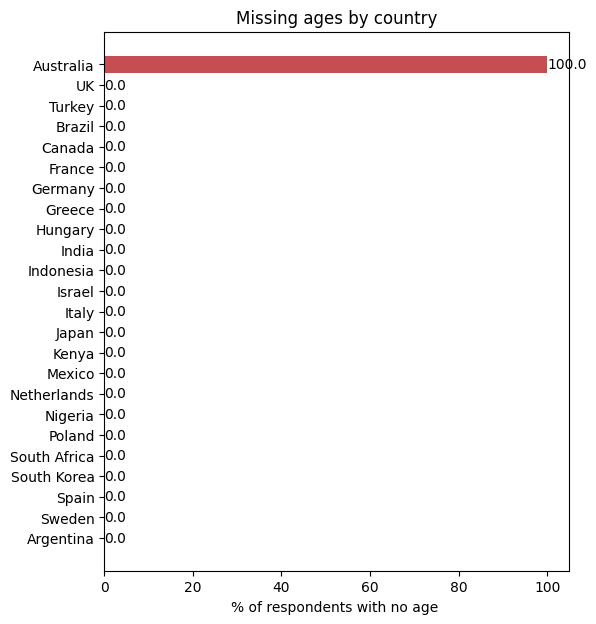

In [162]:
# Fig 1: share of respondents with no age , by country 
# (OLD figure 2)
missing_age = df.groupby('country_name')['age'].apply(lambda s: s.isna().mean() * 100).sort_values()
plt.figure(figsize=(6, 7))
bars = plt.barh(missing_age.index, missing_age.values, color='#C44E52')
plt.bar_label(bars, fmt='%.1f'); plt.xlabel('% of respondents with no age '); plt.title('Missing ages by country')
plt.show()

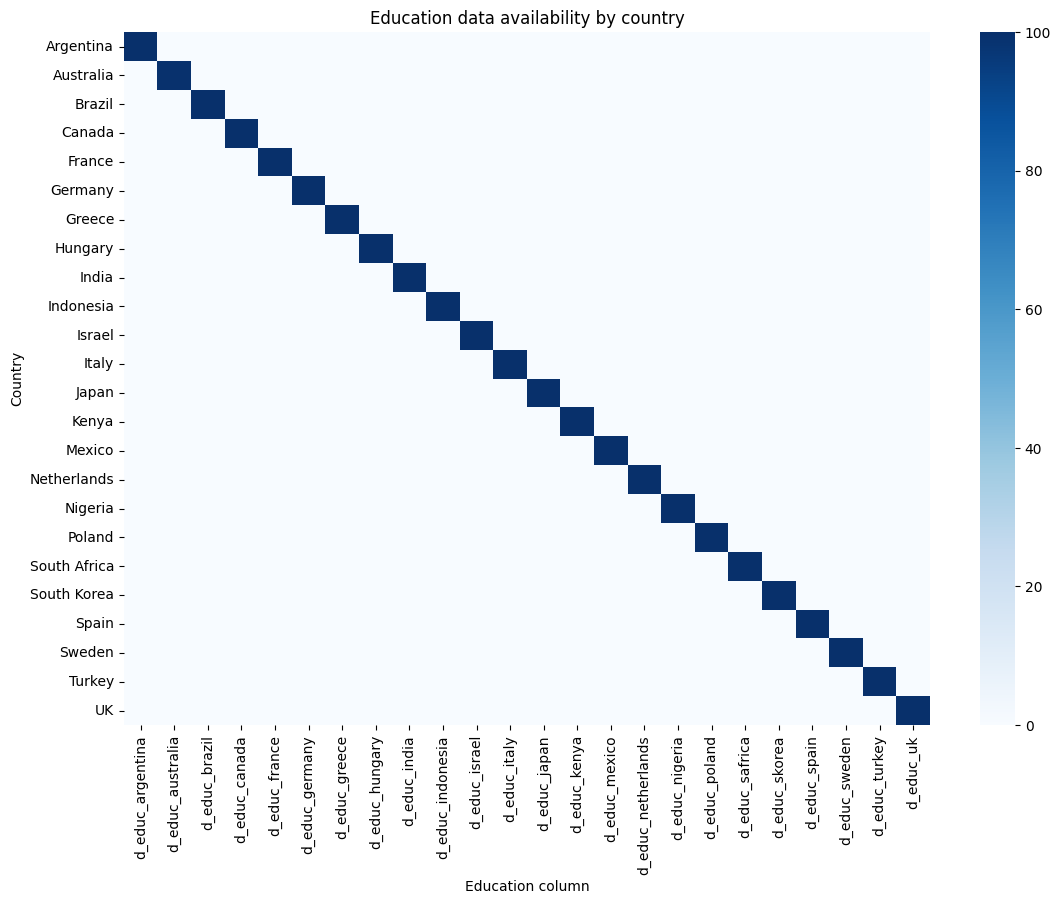

In [163]:
# Fig 2: Share of missing values in education columns

education = ['d_educ_argentina',
             'd_educ_australia',
             'd_educ_brazil',
             'd_educ_canada',
             'd_educ_france',
             'd_educ_germany',
             #'d_educ_germany_vocational',
             'd_educ_greece',
             'd_educ_hungary',
             'd_educ_india',
             'd_educ_indonesia',
             'd_educ_israel',
             #'d_educ_israel_vocational',
             'd_educ_italy',
             'd_educ_japan',
             'd_educ_kenya',
             'd_educ_mexico',
             'd_educ_netherlands',
             'd_educ_nigeria',
             'd_educ_poland',
             'd_educ_safrica',
             'd_educ_skorea',
             'd_educ_spain',
             'd_educ_sweden',
             'd_educ_turkey',
             'd_educ_uk']

# Fig 2: Share of non-null education values, by country and education column
education_availability = df.groupby('country_name')[education].agg(
    lambda s: s.notna().mean() * 100
)

plt.figure(figsize=(13, 9))
sns.heatmap(education_availability, cmap='Blues', vmin=0, vmax=100)
plt.xlabel('Education column')
plt.ylabel('Country')
plt.title('Education data availability by country')
plt.xticks(rotation=90)
plt.show()

### Dealing with missing values

#### Age

In figure 1 we can see that the missing values in age are almost certinley  caused by Australian respondents.

Since Australia stores age information separately in age_australia as bands of age, we can combine both age & australia_age into a single column of age bands  to address this.

In [164]:
# Combine exact ages and Australian age bands into a single age-group column 
age_labels = ['18-29', '30-49', '50-64', '65+']

df['age_grp'] = pd.cut(df['age'].replace("DK/Refused", np.nan), bins=[17, 29, 49, 64, 200], labels=age_labels)

# use the Australian age bands where exact age is unavailable.
australian_age_grp = {1: '18-29', 2: '30-49', 3: '50-64', 4: '65+'}
df['age_grp'] = df['age_grp'].astype(object).fillna(df['age_australia'].map(australian_age_grp))
df['age_grp'] = pd.Categorical(df['age_grp'], categories=age_labels, ordered=True)

print(df['age_grp'].value_counts(dropna=False))



age_grp
30-49    9697
50-64    6499
18-29    6295
65+      5546
NaN       296
Name: count, dtype: int64


We'll investigate the nan values to ensure that all of them are from once marked "DK/Refused"

In [165]:
# Investigate missing age groups
df.loc[df['age_grp'].isna(), ['country_name', 'age', 'age_australia']].value_counts(dropna=False)

country_name  age         age_australia
Japan         DK/Refused  NaN              70
UK            DK/Refused  NaN              58
Canada        DK/Refused  NaN              49
Poland        DK/Refused  NaN              37
Germany       DK/Refused  NaN              22
Spain         DK/Refused  NaN              14
France        DK/Refused  NaN              10
Italy         DK/Refused  NaN               9
Netherlands   DK/Refused  NaN               8
Hungary       DK/Refused  NaN               6
India         DK/Refused  NaN               4
Turkey        DK/Refused  NaN               4
Australia     NaN         NaN               2
Greece        DK/Refused  NaN               1
Sweden        DK/Refused  NaN               1
Nigeria       DK/Refused  NaN               1
Name: count, dtype: int64


Of the 296, 294 we're indeed once marked with only 2 never being marked as they were from australlia & didn't have any age data in age_australlia either.



In [166]:
df['age_grp'] = df['age_grp'].cat.add_categories("DK/Refused")

df.loc[
    df['age'].eq("DK/Refused") & df['age_grp'].isna(),
    'age_grp'
] = "DK/Refused"


#### Education

Based on figure 2 the missing values in the education columns are caused by each col only recording the education of respondents from 1 specific country.

Since each education is for 1 country they won't overlap and thus they can be combined into a single education column.


(think vocational for germany and israel are recording differnt stuff)

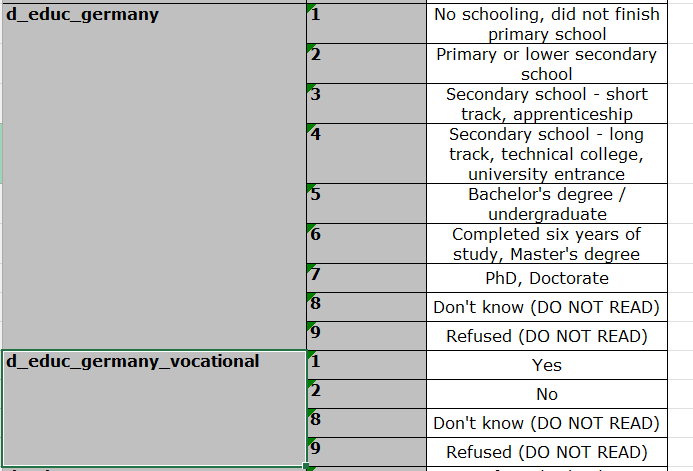

In [167]:
# Combine the different education columns into one
education = ['d_educ_argentina',
             'd_educ_australia',
             'd_educ_brazil',
             'd_educ_canada',
             'd_educ_france',
             'd_educ_germany',
             #'d_educ_germany_vocational',
             'd_educ_greece',
             'd_educ_hungary',
             'd_educ_india',
             'd_educ_indonesia',
             'd_educ_israel',
             #'d_educ_israel_vocational',
             'd_educ_italy',
             'd_educ_japan',
             'd_educ_kenya',
             'd_educ_mexico',
             'd_educ_netherlands',
             'd_educ_nigeria',
             'd_educ_poland',
             'd_educ_safrica',
             'd_educ_skorea',
             'd_educ_spain',
             'd_educ_sweden',
             'd_educ_turkey',
             'd_educ_uk']

df['education'] = df[education].replace("DK/Refused", 404).max(axis=1).replace(404, "DK/Refused")

print(df['education'].value_counts(dropna=False))

education
DK/Refused    4803
7.0           4510
5.0           3711
4.0           3623
6.0           2719
3.0           2712
10.0          1639
2.0           1628
1.0           1178
11.0           921
13.0           342
12.0           167
14.0           105
8.0            105
15.0            66
9.0             61
17.0            13
16.0            10
None             8
18.0             6
19.0             5
20.0             1
Name: count, dtype: int64


We see that there are still 8 none response so we use .loc to investiagte them.

In [168]:
df.loc[df['education'].isna() == True]

,country,weight,ai_heard,ai_cncexc,aireg_us,aireg_china,aireg_eu,aireg_country,age,age_australia,...,d_educ_skorea,d_educ_spain,d_educ_sweden,d_educ_turkey,d_educ_uk,country_name,ai_heard_raw,ai_cncexc_raw,age_grp,education
11186,13,5.892368,1,3,2,4,3,2,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,Australia,1,3,65+,None
11271,13,4.593190,2,3,4,4,1,1,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,Australia,2,3,65+,None
11361,13,2.363250,1,2,4,4,3,3,NaN,1.0,...,NaN,NaN,NaN,NaN,NaN,Australia,1,2,18-29,None
12218,13,2.314369,1,3,1,2,3,1,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,Australia,1,3,65+,None
12231,13,4.939633,3,2,4,4,3,3,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,Australia,3,2,65+,None
12341,13,2.225401,2,3,8,8,8,8,NaN,1.0,...,NaN,NaN,NaN,NaN,NaN,Australia,2,3,18-29,None
12644,13,3.611892,2,2,4,4,2,2,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,Australia,2,2,65+,None
12785,13,5.547409,2,3,2,2,2,2,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,Australia,2,3,65+,None


We can see that the 8 indviduals with missing data are all from austrlia.

(do we drop or keep to show that some data is missing?)

# Validating Preprocessing

Calcuate the weightings to account for sampling bias in Q30 & q31  due to the diffrence in countrie's populations and then used topline to comapre results agints Pew published figures for verfication of preorpcessign

In [169]:
def weighted_pct(d, var, value):
    d = d.dropna(subset=[var, 'weight'])
    return d.loc[d[var] == value, 'weight'].sum() / d['weight'].sum() * 100

def topline(var_raw, codes, names, countries):
    d = df[df['country_name'].isin(countries)].copy()
    d['cat'] = d[var_raw].where(d[var_raw].isin(codes), 99)
    t = d.pivot_table(index='country_name', columns='cat', values='weight', aggfunc='sum')
    t = t.div(t.sum(axis=1), axis=0) * 100
    t.columns = [names.get(c, 'DK/Refused') for c in t.columns]
    return t.round(0)
 
check_countries = ['UK', 'South Africa', 'Japan']
print(topline('ai_heard_raw', [1, 2, 3], {1: 'A lot', 2: 'A little', 3: 'Nothing'}, check_countries))
print(topline('ai_cncexc_raw', [1, 2, 3], {1: 'Excited', 2: 'Concerned', 3: 'Equally'}, check_countries))


 

# % who've heard "a lot" about AI per country and age group, weighted vs unweighted (the difference shows what weighting changes)
grp = df[df['age_grp'] != "DK/Refused"].groupby(['country_name', 'age_grp'],observed=True)
heard_weighted = grp[['ai_heard', 'weight']].apply(lambda g: weighted_pct(g, 'ai_heard', 1)).unstack()
heard_unweighted = grp['ai_heard'].apply(lambda s: (s.dropna() == 1).mean() * 100).unstack()
print(heard_weighted.round(1))
print((heard_weighted - heard_unweighted).round(1))
 
# Number of respondents in each country x age group (small groups mean wide uncertainty later)
print(grp.size().unstack())

              A lot  A little  Nothing  DK/Refused
country_name                                      
Japan          53.0      36.0     11.0         0.0
South Africa   30.0      31.0     34.0         6.0
UK             41.0      49.0     10.0         0.0
              Excited  Concerned  Equally  DK/Refused
country_name                                         
Japan            16.0       28.0     55.0         1.0
South Africa     18.0       30.0     42.0        10.0
UK               13.0       39.0     46.0         2.0
age_grp       18-29  30-49  50-64   65+
country_name                           
Argentina      38.2   23.3   17.1  10.2
Australia      66.7   48.5   35.8  23.5
Brazil         38.7   19.6   14.1  10.8
Canada         54.6   46.2   37.8  26.0
France         77.1   60.4   43.0  29.6
Germany        69.2   58.2   43.5  38.6
Greece         75.0   40.4   26.4  12.8
Hungary        63.7   44.5   34.7  19.0
India          20.4   12.3    9.0   7.9
Indonesia      33.5   15.4    7.1  

# Exporting csv

In [170]:
df.head()

,country,weight,ai_heard,ai_cncexc,aireg_us,aireg_china,aireg_eu,aireg_country,age,age_australia,...,d_educ_skorea,d_educ_spain,d_educ_sweden,d_educ_turkey,d_educ_uk,country_name,ai_heard_raw,ai_cncexc_raw,age_grp,education
0,2,0.592005,2,2,2,8,2,2,77.0,NaN,...,NaN,NaN,NaN,NaN,NaN,Canada,2,2,65+,10.0
1,2,0.446814,2,3,4,4,2,2,72.0,NaN,...,NaN,NaN,NaN,NaN,NaN,Canada,2,3,65+,10.0
2,2,1.120110,2,2,4,4,8,2,74.0,NaN,...,NaN,NaN,NaN,NaN,NaN,Canada,2,2,65+,6.0
3,2,0.695317,2,2,4,4,1,2,78.0,NaN,...,NaN,NaN,NaN,NaN,NaN,Canada,2,2,65+,DK/Refused
4,2,0.369352,1,3,3,3,2,2,67.0,NaN,...,NaN,NaN,NaN,NaN,NaN,Canada,1,3,65+,10.0


Convert DK/REFUSED to nan values if not diffreating between refused and missing in eda

In [ ]:
df = df.replace('DK/Refused', np.nan)

In [ ]:
df.to_csv('processed_data.csv', index=False)